In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('business-news-caro.csv')
df.head()

,uri,canonical,country,sector,themes,sentence_id,polarity,doc_id,date,document_url,title
0,Date,2026-10-22,NaN,NaN,['finance'],1,NaN,C:\Users\LENOVO\Desktop\Projcet wowool\othmane...,['2026-10-22'],['https://help.bbc.com/hc/'],"['Barclays cutting 5,000 jobs as it increases ..."
1,Company,Barclays,UK,"banking,financials",['finance'],3,NaN,C:\Users\LENOVO\Desktop\Projcet wowool\othmane...,['2026-10-22'],['https://help.bbc.com/hc/'],"['Barclays cutting 5,000 jobs as it increases ..."
2,Company,Barclays,UK,"banking,financials",['finance'],4,NaN,C:\Users\LENOVO\Desktop\Projcet wowool\othmane...,['2026-10-22'],['https://help.bbc.com/hc/'],"['Barclays cutting 5,000 jobs as it increases ..."
3,Company,Barclays,UK,"banking,financials",['finance'],6,NaN,C:\Users\LENOVO\Desktop\Projcet wowool\othmane...,['2026-10-22'],['https://help.bbc.com/hc/'],"['Barclays cutting 5,000 jobs as it increases ..."
4,Company,Barclays,UK,"banking,financials",['finance'],9,NaN,C:\Users\LENOVO\Desktop\Projcet wowool\othmane...,['2026-10-22'],['https://help.bbc.com/hc/'],"['Barclays cutting 5,000 jobs as it increases ..."


In [4]:
df.shape

(117852, 11)

In [5]:
df.columns

Index(['uri', 'canonical', 'country', 'sector', 'themes', 'sentence_id',
       'polarity', 'doc_id', 'date', 'document_url', 'title'],
      dtype='str')

### Description of each column : 

1. Uri : Represents the type of annotation extracted from the news article, such as Company, MoneyAmount, Date, or CompanyPerformance.

2. canonical : Contains the normalized value of the extracted entity or annotation, such as a company name, financial amount, or event description.

3. country : Indicates the country associated with the extracted entity.

4. sector : Represents the economic sector associated with the company or entity.

5. themes : Contains the thematic categories assigned to the news article, describing its main topics.

6. sentence_id : Identifies the sentence from which the annotation was extracted within the document.
 
7. ploarity : ###

8. doc_id : Provides the document identifier, used to associate annotations with their original news article.

9. date : Indicates the publication date of the news article.

10. document_url = Contains the URL of the original news article.

11. title : Contains the title of the original news article.

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 117852 entries, 0 to 117851
Data columns (total 11 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   uri           117852 non-null  str  
 1   canonical     117852 non-null  str  
 2   country       32157 non-null   str  
 3   sector        41319 non-null   str  
 4   themes        117821 non-null  str  
 5   sentence_id   117852 non-null  int64
 6   polarity      4537 non-null    str  
 7   doc_id        117852 non-null  str  
 8   date          117852 non-null  str  
 9   document_url  117228 non-null  str  
 10  title         117852 non-null  str  
dtypes: int64(1), str(10)
memory usage: 9.9 MB


In [7]:
df.isnull().sum().sort_values(ascending=False)

polarity        113315
country          85695
sector           76533
document_url       624
themes              31
canonical            0
uri                  0
sentence_id          0
doc_id               0
date                 0
title                0
dtype: int64

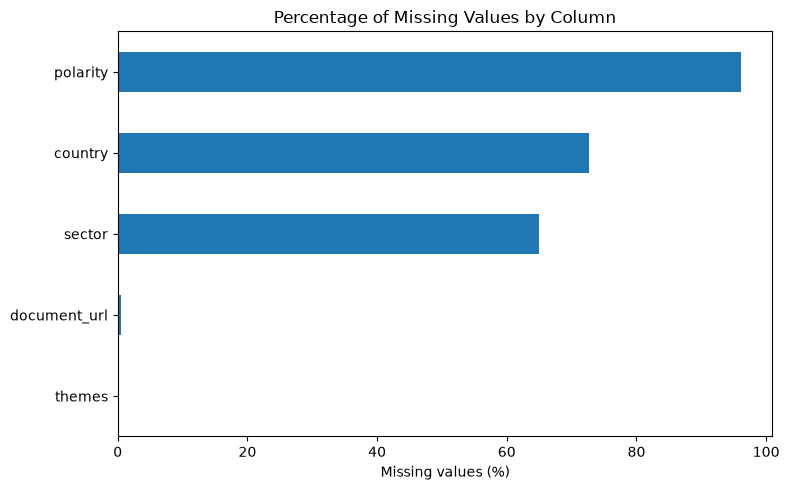

In [8]:
missing_pct = df.isnull().mean().mul(100)
missing_pct = missing_pct[missing_pct > 0].sort_values()

missing_pct.plot(kind="barh", figsize=(8, 5))

plt.xlabel("Missing values (%)")
plt.title("Percentage of Missing Values by Column")
plt.tight_layout()
plt.show()

 We have 6680 duplicates

In [9]:
dup  = sum(df.duplicated())
f"{dup} duplicates"

'6680 duplicates'

In [10]:
df.describe()

,sentence_id
count,117852.000000
mean,38.548230
std,94.186839
min,1.000000
25%,9.000000
50%,22.000000
75%,42.000000
max,2202.000000


#### Analysis of Numerical value : 

The dataset contains only one numerical column: `sentence_id`.

However, this column represents a sentence identifier rather than a quantitative variable. Therefore, statistical analysis such as mean, median, standard deviation, and numerical distribution is not meaningful.

It will instead be used as an identifier for sentence-level analysis when needed.

### Analysis of Categorial columns

Select all categorical columns

In [11]:
cat_cols = [
    "uri",
    "canonical",
    "country",
    "sector",
    "themes",
    "polarity"
]

df[cat_cols].dtypes

uri          str
canonical    str
country      str
sector       str
themes       str
polarity     str
dtype: object

In [12]:
cardinality = pd.DataFrame({
    "n_unique": df[cat_cols].nunique(),
    "missing": df[cat_cols].isna().sum(),
})

cardinality.sort_values(
     "n_unique",
     ascending=False
)

,n_unique,missing
canonical,27720,0
sector,156,76533
themes,129,31
country,66,85695
uri,13,0
polarity,3,113315


Dominance of columns


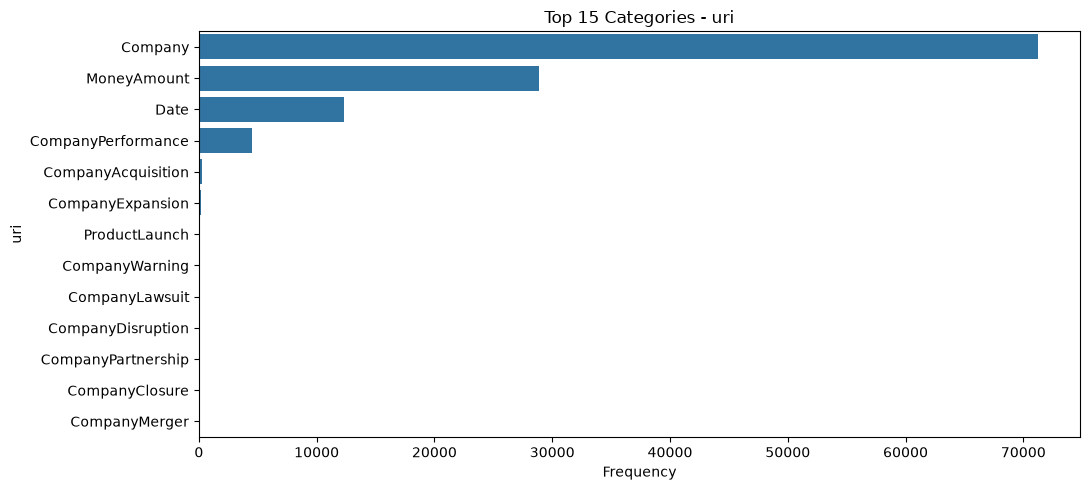

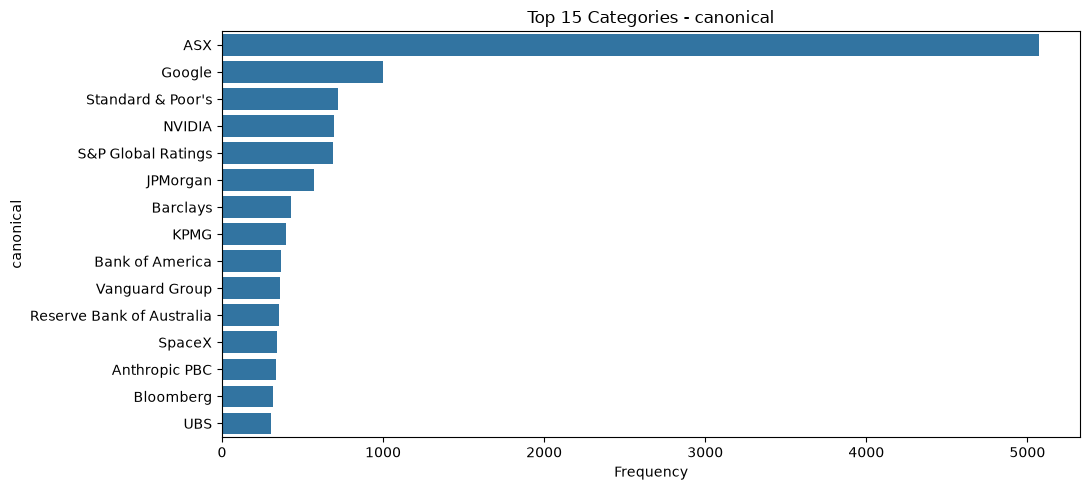

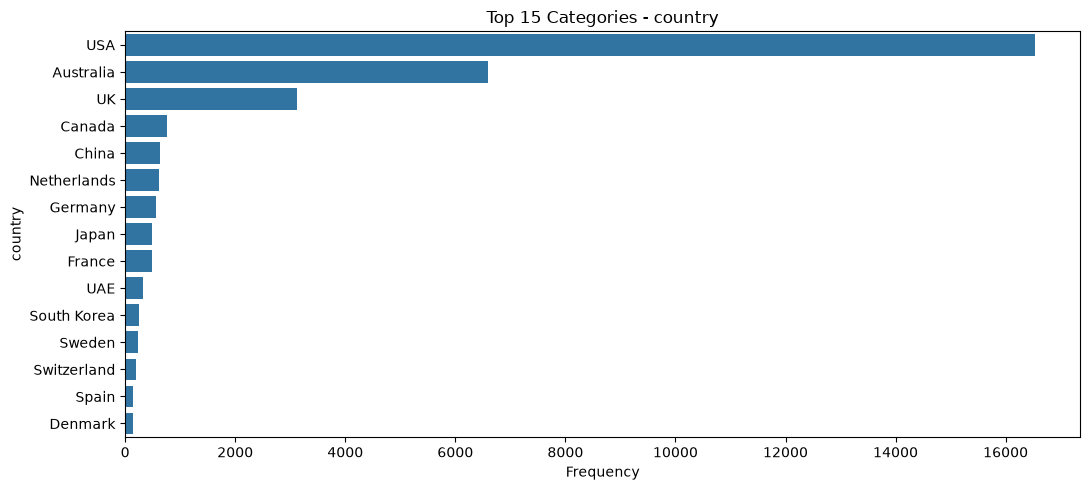

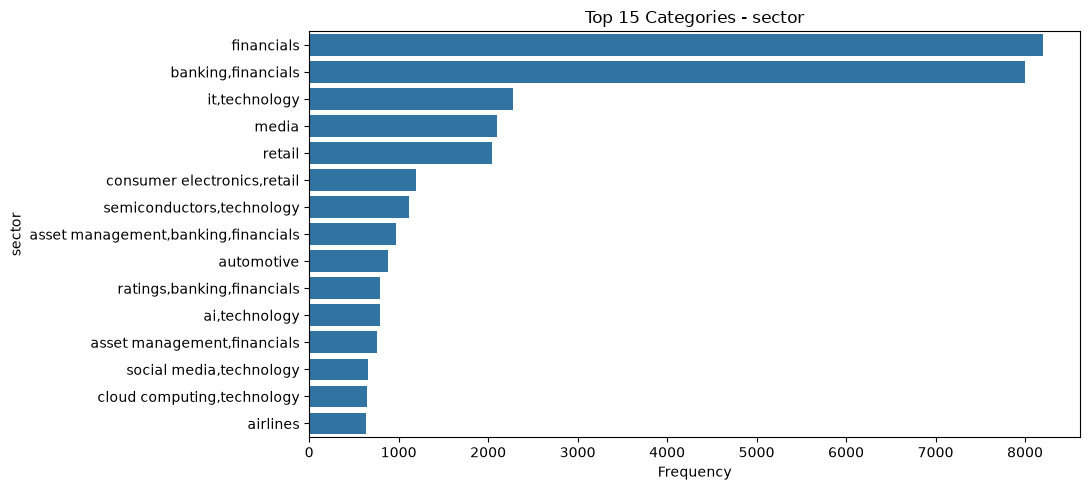

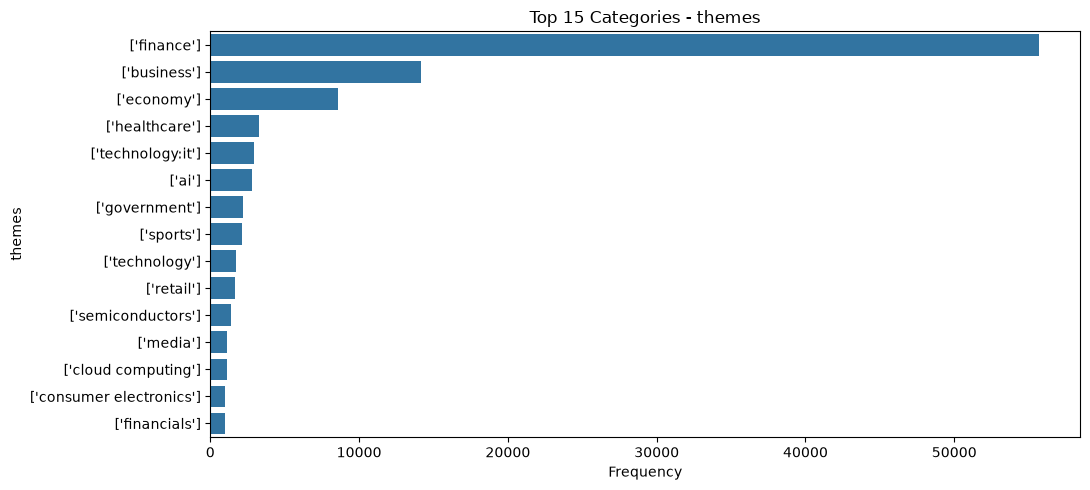

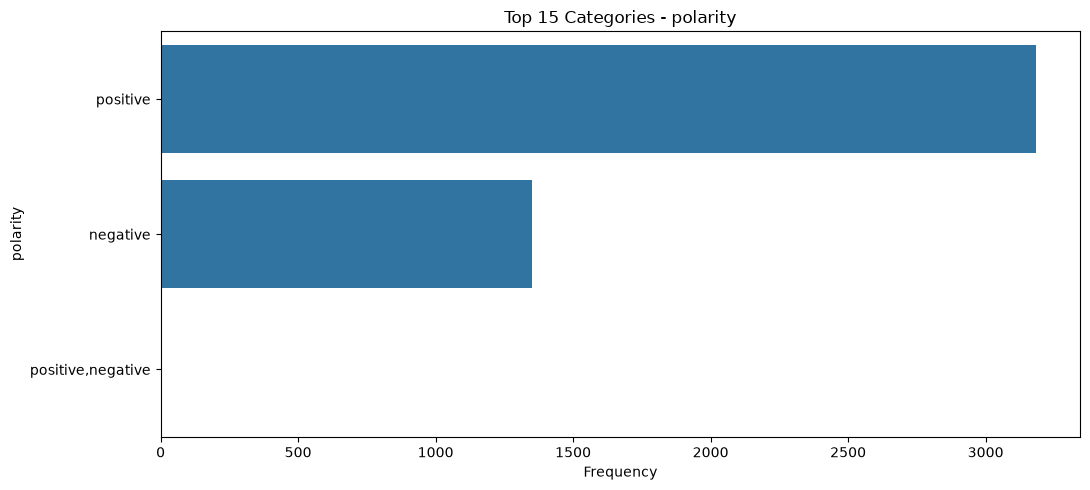

In [13]:
for col in cat_cols:
    counts = df[col].value_counts().head(15)

    plt.figure(figsize=(11, 5))

    sns.barplot(
        x=counts.values,
        y=counts.index
    )

    plt.title(f"Top 15 Categories - {col}")
    plt.xlabel("Frequency")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

Data Quality Analysis

1. Missing Values Analysis : 

In [14]:
missing_cat = pd.DataFrame({
    "missing_count": df[cat_cols].isna().sum(),
    "missing_percentage": df[cat_cols].isna().mean() * 100
})

missing_cat.sort_values(
    "missing_percentage",
    ascending=False
)

,missing_count,missing_percentage
polarity,113315,96.150256
country,85695,72.714082
sector,76533,64.939925
themes,31,0.026304
canonical,0,0.000000
uri,0,0.000000


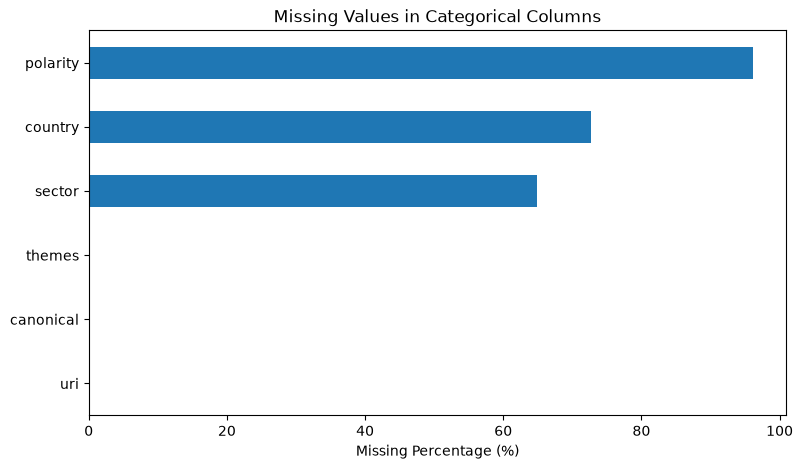

In [15]:
missing_cat["missing_percentage"].sort_values().plot(
    kind="barh",
    figsize=(9, 5)
)

plt.title("Missing Values in Categorical Columns")
plt.xlabel("Missing Percentage (%)")
plt.show()

2. Inconsistent labels

In [16]:
for col in cat_cols:
        print(f"\n--- {col} ---")
        print("Empty strings:",(df[col].str.strip() == "").sum())
        print("Values with leading/trailing spaces:",(df[col] != df[col].str.strip()).sum())


--- uri ---
Empty strings: 0
Values with leading/trailing spaces: 0

--- canonical ---
Empty strings: 0
Values with leading/trailing spaces: 0

--- country ---
Empty strings: 0
Values with leading/trailing spaces: 85695

--- sector ---
Empty strings: 0
Values with leading/trailing spaces: 76542

--- themes ---
Empty strings: 0
Values with leading/trailing spaces: 31

--- polarity ---
Empty strings: 0
Values with leading/trailing spaces: 113315


3. Detect capitalization inconsistencies

In [17]:
for col in cat_cols:
    values = df[col].dropna().unique()
    normalized = pd.Series(values).str.lower()
    duplicates = normalized[
        normalized.duplicated(keep=False)
    ]
    print(f"\n{col}:")
    print(duplicates.unique())


uri:
<StringArray>
[]
Length: 0, dtype: str

canonical:
<StringArray>
[                'sprint',                   'save',           'arm holdings',
               'softbank',                   'time',              'blackrock',
           'hugging face',                 'micron',             'moneyfacts',
              'bloomberg',
 ...
                   'scor',                 'acumen', 'owl technology finance',
          'c$5.7 billion',              'cable one',       'sharplink gaming',
       'public education',         'royalty pharma',      'endeavor catalyst',
        'synergy capital']
Length: 230, dtype: str

country:
<StringArray>
['uk']
Length: 1, dtype: str

sector:
<StringArray>
['supermarkets']
Length: 1, dtype: str

themes:
<StringArray>
[]
Length: 0, dtype: str

polarity:
<StringArray>
[]
Length: 0, dtype: str


### Analysis the annoniation and entities (Specific Analysis for wowool) : 

1. Uri :

In [18]:
uri_counts = df["uri"].value_counts()
print(uri_counts)

uri
Company               71248
MoneyAmount           28899
Date                  12343
CompanyPerformance     4537
CompanyAcquisition      268
CompanyExpansion        212
ProductLaunch           132
CompanyWarning           81
CompanyLawsuit           68
CompanyDisruption        30
CompanyPartnership       20
CompanyClosure           12
CompanyMerger             2
Name: count, dtype: int64


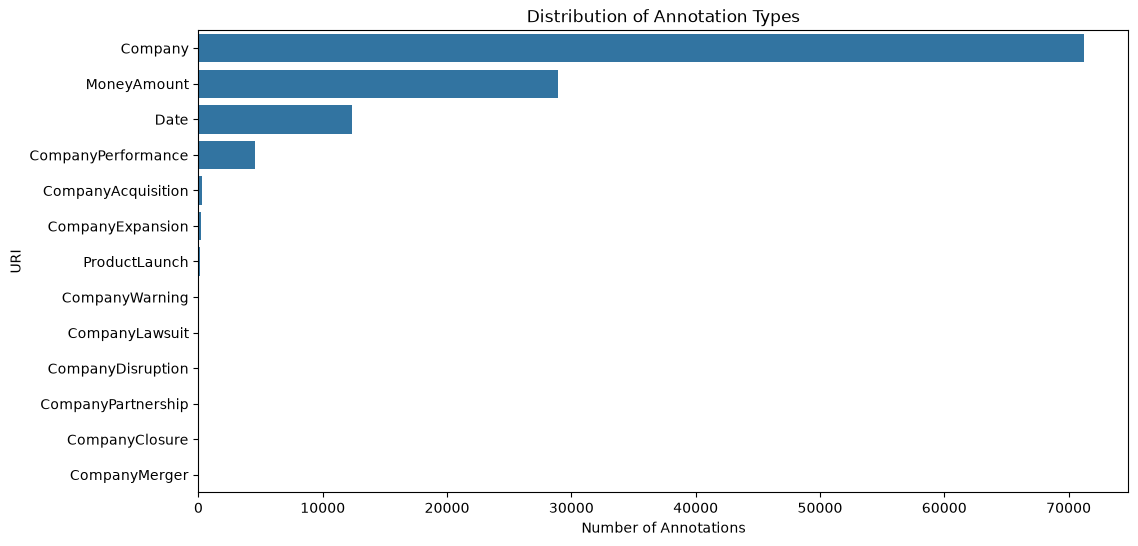

In [19]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=uri_counts.values,
    y=uri_counts.index
)

plt.title("Distribution of Annotation Types")
plt.xlabel("Number of Annotations")
plt.ylabel("URI")
plt.show()

2. Analyze canonical according to URI:

In [20]:
for uri_type in df["uri"].unique():

    subset = df.loc[
        df["uri"] == uri_type,
        "canonical"
    ]

    print(f"\n--- {uri_type} ---")
    print("Unique:", subset.nunique())
    print(subset.value_counts().head(10))


--- Date ---
Unique: 1738
canonical
2026-08-25            158
June 30, 2026         151
June 2026             111
June 30               109
September 30, 2026     91
August 6th             88
2026-10-22             84
2026-09-14             83
2026-10-01             83
2026-09-08             82
Name: count, dtype: int64

--- Company ---
Unique: 6565
canonical
ASX                   5073
Google                 998
Standard & Poor's      718
NVIDIA                 694
S&P Global Ratings     692
JPMorgan               573
Barclays               431
KPMG                   398
Bank of America        364
Vanguard Group         362
Name: count, dtype: int64

--- MoneyAmount ---
Unique: 14531
canonical
$ 100            131
$ 1 billion      117
$ 500 million     74
$ 20 billion      67
$ 100 million     67
$ 25,000          60
$ 26,000          58
$ 90              56
$ 0.01            56
$ 2 billion       55
Name: count, dtype: int64

--- CompanyLawsuit ---
Unique: 59
canonical
Bank of America

In [21]:
company_df = df[df["uri"] == "Company"]
company_counts = company_df["canonical"].value_counts()
company_counts.head(20)

canonical
ASX                          5073
Google                        998
Standard & Poor's             718
NVIDIA                        694
S&P Global Ratings            692
JPMorgan                      573
Barclays                      431
KPMG                          398
Bank of America               364
Vanguard Group                362
Reserve Bank of Australia     357
SpaceX                        342
Anthropic PBC                 338
Bloomberg                     317
UBS                           303
Invesco                       296
Citigroup                     291
Amazon                        288
Meta                          284
OpenAI                        280
Name: count, dtype: int64

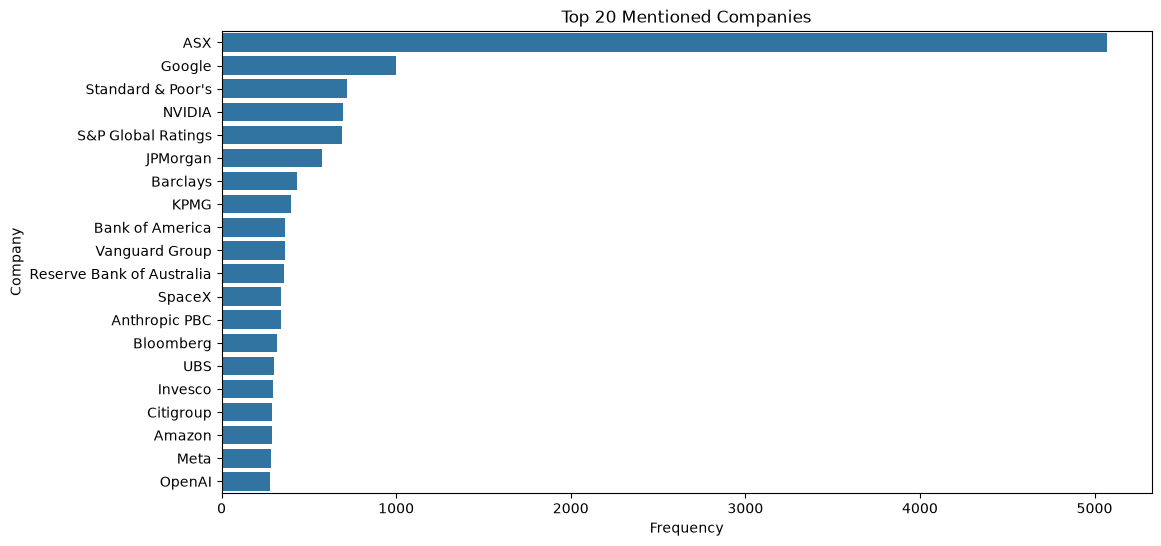

In [22]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=company_counts.head(20).values,
    y=company_counts.head(20).index
)

plt.title("Top 20 Mentioned Companies")
plt.xlabel("Frequency")
plt.ylabel("Company")
plt.show()

3. Country Analysis : 

3.1 Analysis of country according of Company anotations : 

In [28]:
company_df = df[df["uri"] == "Company"]
country_counts = company_df["country"].value_counts()
country_counts.head()

country
USA          16525
Australia     6597
UK            3118
Canada         766
China          631
Name: count, dtype: int64

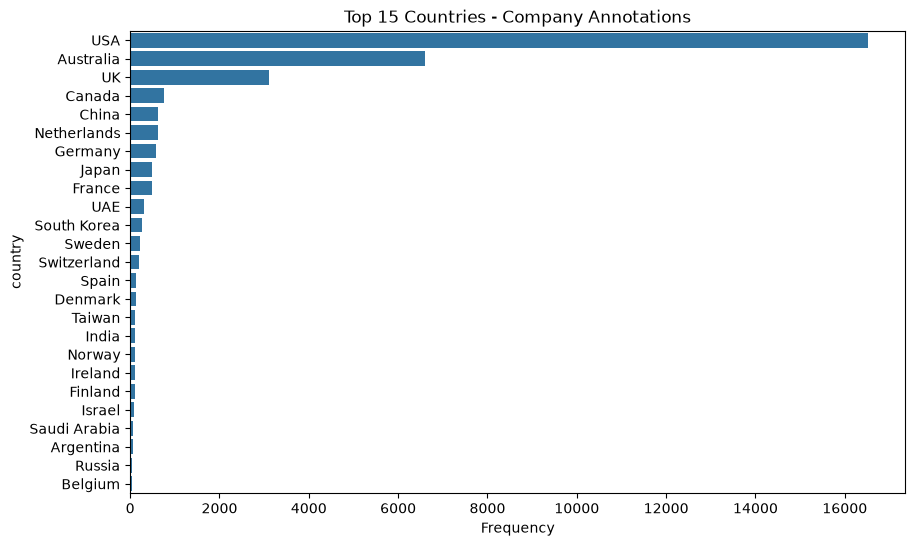

In [31]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=country_counts.head(25).values,
    y=country_counts.head(25).index
)

plt.title("Top 15 Countries - Company Annotations")
plt.xlabel("Frequency")
plt.show()

4. Sector Analysis : 

In [32]:
sector_counts = company_df["sector"].value_counts()
sector_counts.head(20)

sector
financials                             8204
banking,financials                     8002
it,technology                          2281
media                                  2104
retail                                 2040
consumer electronics,retail            1192
semiconductors,technology              1121
asset management,banking,financials     971
automotive                              876
ratings,banking,financials              796
ai,technology                           789
asset management,financials             762
social media,technology                 662
cloud computing,technology              651
airlines                                633
financials,banking                      623
aerospace                               612
insurance,financials                    604
oil,energy                              604
mining                                  536
Name: count, dtype: int64

4.1 Separate sectors to analyze each sector individually

In [33]:
sector_exploded = (
    company_df["sector"]
    .dropna()
    .str.split(",")
    .explode()
    .str.strip()
)

sector_counts_individual = sector_exploded.value_counts()

sector_counts_individual.head(20)

sector
financials               21276
banking                  11071
technology                6256
retail                    3293
it                        2522
media                     2119
asset management          1823
consumer electronics      1212
semiconductors            1179
energy                    1159
oil                        940
insurance                  885
automotive                 877
ratings                    869
cloud computing            865
ai                         808
social media               665
aerospace                  657
airlines                   633
professional services      622
Name: count, dtype: int64

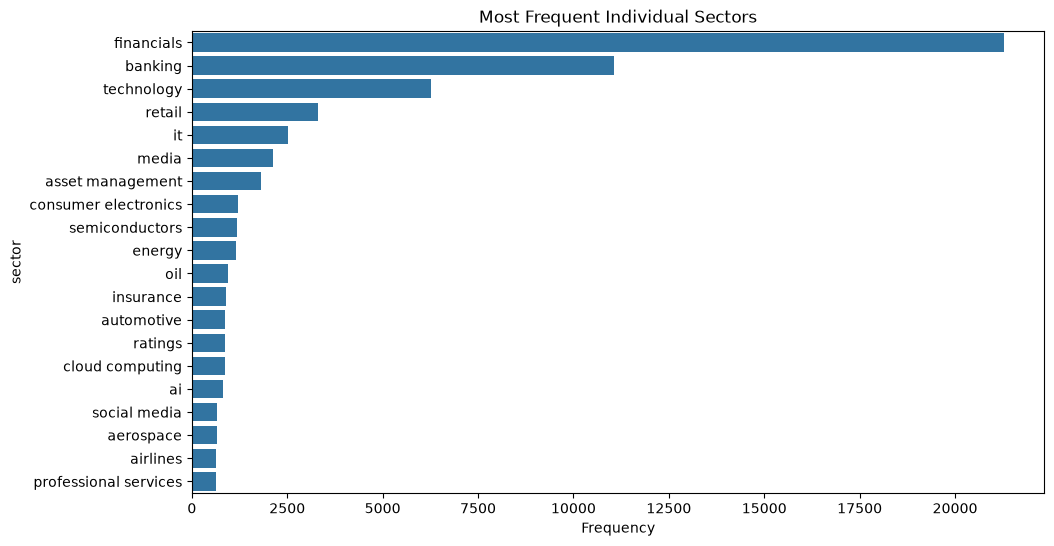

In [34]:
plt.figure(figsize=(11, 6))

sns.barplot(
    x=sector_counts_individual.head(20).values,
    y=sector_counts_individual.head(20).index
)

plt.title("Most Frequent Individual Sectors")
plt.xlabel("Frequency")
plt.show()

5. Themes Analysis :

In [ ]:
import ast

def parse_themes(value):
    if pd.isna(value):
        return []

    try:
        result = ast.literal_eval(value)

        if isinstance(result, list):
            return result
        return [result]
    except (ValueError, SyntaxError):
        return [value]

In [37]:
themes_exploded = (df["themes"].apply(parse_themes).explode().dropna().str.strip())
theme_counts = themes_exploded.value_counts()
theme_counts.head(20)

themes
finance                 55667
business                14186
economy                  8554
healthcare               3294
technology:it            2924
ai                       2796
government               2201
sports                   2138
technology               1751
retail                   1687
semiconductors           1409
media                    1149
cloud computing          1111
consumer electronics     1016
financials                961
politics                  950
law                       815
transportation            680
mining                    656
education                 594
Name: count, dtype: int64

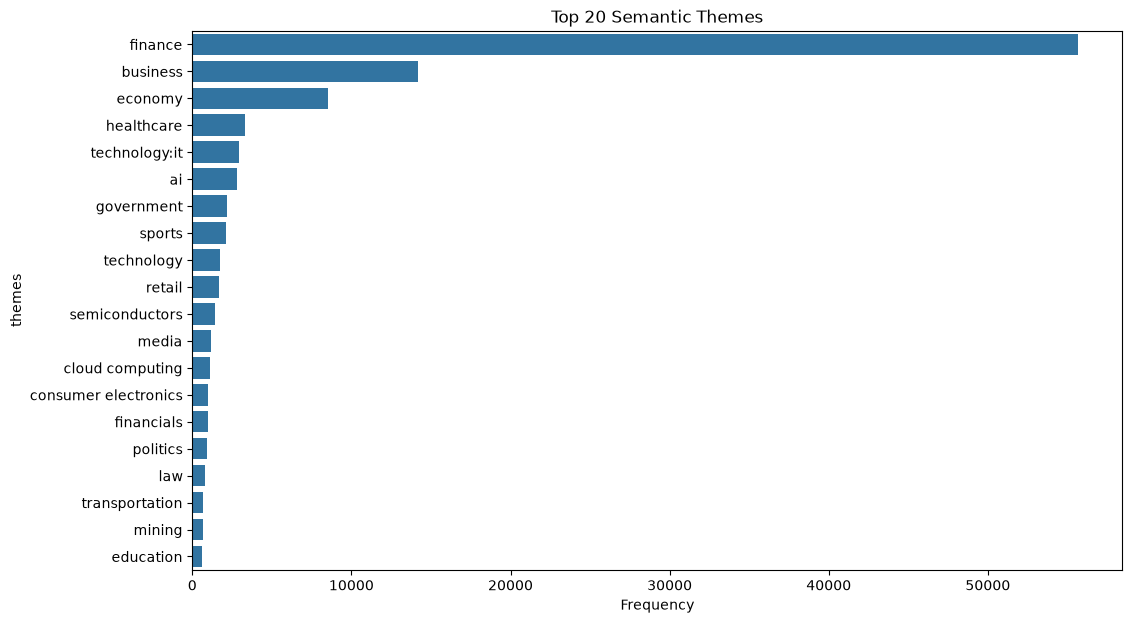

In [38]:
plt.figure(figsize=(12, 7))

sns.barplot(
    x=theme_counts.head(20).values,
    y=theme_counts.head(20).index
)

plt.title("Top 20 Semantic Themes")
plt.xlabel("Frequency")
plt.show()

6. Relationships between categorical variables

6.1 URI Vs Themes : 

In [39]:
uri_theme = pd.crosstab(
    df["uri"],
    themes_exploded.reindex(df.index) if False else df["uri"]
)

In [40]:
theme_data = df[["uri", "themes"]].copy()
theme_data["theme"] = theme_data["themes"].apply(parse_themes)
theme_data = theme_data.explode("theme")
uri_theme = pd.crosstab(
    theme_data["uri"],
    theme_data["theme"]
)
uri_theme

theme,aerospace,agriculture,ai,airlines,business,business:customer support,business:expansion,business:hospitality,business:insurance,business:marketing,...,technology:it,technology:semiconductors,telco,terrorism,tobacco,transportation,travel,utilities,war,weather
uri,,,,,,,,,,,,,,,,,,,,,
Company,306,79,2098,409,8608,18,16,38,52,27,...,1886,35,361,31,28,448,6,181,84,16
CompanyAcquisition,2,0,1,1,50,0,0,0,0,0,...,4,0,4,0,0,6,0,0,0,0
CompanyClosure,0,0,0,0,3,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
CompanyDisruption,0,0,0,0,2,0,0,0,0,0,...,2,0,0,0,0,0,0,0,0,0
CompanyExpansion,2,0,17,0,19,0,2,0,0,0,...,6,0,0,0,0,9,0,0,0,0
CompanyLawsuit,0,0,4,1,3,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
CompanyMerger,0,0,0,0,0,0,0,0,0,0,...,2,0,0,0,0,0,0,0,0,0
CompanyPartnership,0,1,1,1,0,0,0,0,0,0,...,1,0,0,0,0,1,0,0,0,0
CompanyPerformance,28,12,96,24,407,0,0,2,3,3,...,92,0,18,0,0,22,2,14,5,0


#### Normalized : 

In [41]:
uri_theme_pct = pd.crosstab(
    theme_data["uri"],
    theme_data["theme"],
    normalize="index"
) * 100

uri_theme_pct.round(2)

theme,aerospace,agriculture,ai,airlines,business,business:customer support,business:expansion,business:hospitality,business:insurance,business:marketing,...,technology:it,technology:semiconductors,telco,terrorism,tobacco,transportation,travel,utilities,war,weather
uri,,,,,,,,,,,,,,,,,,,,,
Company,0.43,0.11,2.94,0.57,12.08,0.03,0.02,0.05,0.07,0.04,...,2.65,0.05,0.51,0.04,0.04,0.63,0.01,0.25,0.12,0.02
CompanyAcquisition,0.75,0.00,0.37,0.37,18.66,0.00,0.00,0.00,0.00,0.00,...,1.49,0.00,1.49,0.00,0.00,2.24,0.00,0.00,0.00,0.00
CompanyClosure,0.00,0.00,0.00,0.00,25.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,8.33,0.00,0.00,0.00,0.00,0.00,0.00,0.00
CompanyDisruption,0.00,0.00,0.00,0.00,6.67,0.00,0.00,0.00,0.00,0.00,...,6.67,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
CompanyExpansion,0.94,0.00,8.02,0.00,8.96,0.00,0.94,0.00,0.00,0.00,...,2.83,0.00,0.00,0.00,0.00,4.25,0.00,0.00,0.00,0.00
CompanyLawsuit,0.00,0.00,5.88,1.47,4.41,0.00,0.00,0.00,0.00,0.00,...,1.47,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
CompanyMerger,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,100.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
CompanyPartnership,0.00,5.00,5.00,5.00,0.00,0.00,0.00,0.00,0.00,0.00,...,5.00,0.00,0.00,0.00,0.00,5.00,0.00,0.00,0.00,0.00
CompanyPerformance,0.62,0.26,2.12,0.53,8.97,0.00,0.00,0.04,0.07,0.07,...,2.03,0.00,0.40,0.00,0.00,0.48,0.04,0.31,0.11,0.00


6.2 Country vs Sector :

In [42]:
pd.crosstab(
    company_df["country"],
    company_df["sector"]
)

sector,advertising,aerospace,"aerospace,ai",agriculture,ai,"ai,technology",airlines,aluminum,arts,"asset management,banking,financials",...,toys,"toys,retail",transportation,travel,"travel,hospitality",utilities,"utilities,energy","utilities,gas",venture capital,"weapons,aerospace"
country,,,,,,,,,,,,,,,,,,,,,
Argentina,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Australia,0,0,0,0,0,0,68,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Austria,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Belgium,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
"Belgium,UK",0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"USA,Ireland",0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
"USA,Sweden",0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Uk,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


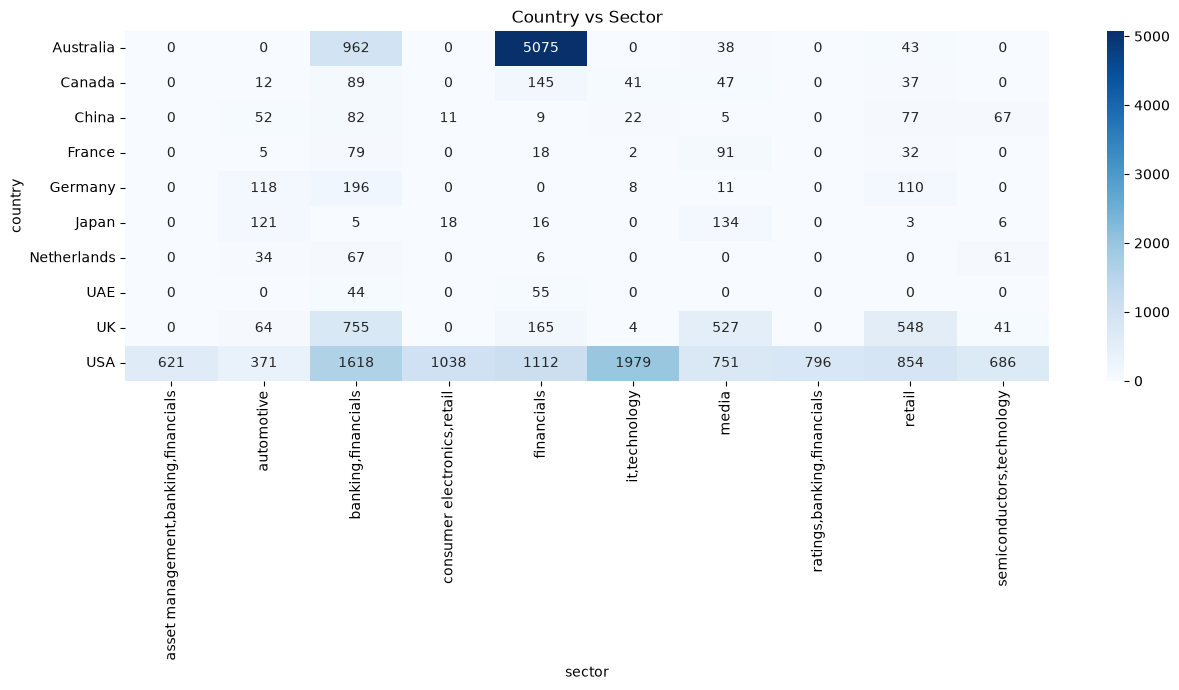

In [47]:
top_countries = company_df["country"].value_counts().head(10).index
top_sectors = company_df["sector"].value_counts().head(10).index

subset = company_df[company_df["country"].isin(top_countries) & company_df["sector"].isin(top_sectors)]

plt.figure(figsize=(13, 7))
sns.heatmap( pd.crosstab(subset["country"], subset["sector"]),
    annot=True,
    fmt="d",
    cmap="Blues",
)
plt.title("Country vs Sector")
plt.tight_layout()
plt.show()